#Fourier Transform
#Task 1:

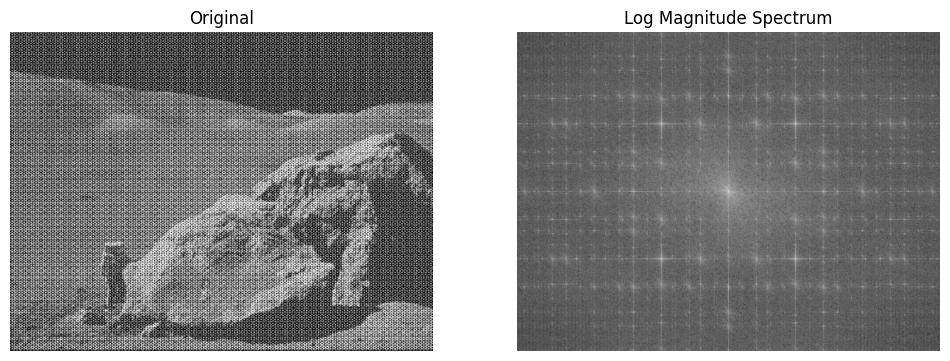

In [15]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

source_image = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

image_float = np.float32(source_image)
height, width = image_float.shape
center_y, center_x = height // 2, width // 2

complex_spectrum = cv.dft(image_float, flags=cv.DFT_COMPLEX_OUTPUT)
centered_spectrum = np.fft.fftshift(complex_spectrum, axes=(0, 1))


def log_magnitude(spectrum):
    real_part = spectrum[:, :, 0]
    imag_part = spectrum[:, :, 1]
    amplitude = cv.magnitude(real_part, imag_part)
    return np.log1p(amplitude)


def inverse_dft(spectrum):
    unshifted = np.fft.ifftshift(spectrum, axes=(0, 1))
    return cv.idft(
        unshifted,
        flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT
    )


def show_gray(data, title, normalize=False):
    if normalize:
        data = cv.normalize(data, None, 0, 255, cv.NORM_MINMAX)
    plt.imshow(data, cmap='gray')
    plt.title(title)
    plt.axis('off')


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
show_gray(source_image, 'Original')

plt.subplot(1, 2, 2)
show_gray(log_magnitude(centered_spectrum), 'Log Magnitude Spectrum')

plt.show()

# Task2. Gaussian High Pass Filter

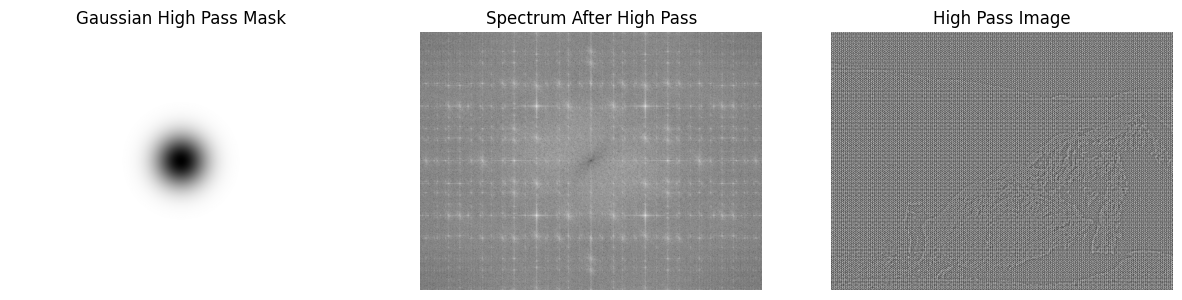

In [16]:
def gaussian_high_pass(shape, cutoff, cy, cx):
    h, w = shape
    y_grid, x_grid = np.meshgrid(
        np.arange(h) - cy,
        np.arange(w) - cx,
        indexing='ij'
    )
    distance_sq = x_grid ** 2 + y_grid ** 2
    return 1.0 - np.exp(-distance_sq / (2.0 * cutoff ** 2))


high_pass_cutoff = 40.0
high_pass_mask = gaussian_high_pass(
    (height, width), high_pass_cutoff, center_y, center_x
)

two_channel_hp = np.dstack([high_pass_mask, high_pass_mask])
high_pass_spectrum = centered_spectrum * two_channel_hp
high_pass_image = inverse_dft(high_pass_spectrum)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
show_gray(high_pass_mask, 'Gaussian High Pass Mask')

plt.subplot(1, 3, 2)
show_gray(log_magnitude(high_pass_spectrum), 'Spectrum After High Pass')

plt.subplot(1, 3, 3)
show_gray(high_pass_image, 'High Pass Image', normalize=True)

plt.show()

# Task3 Convolution using Notch Filtering

Detected spectral peaks: [(np.int64(297), np.int64(216)), (np.int64(297), np.int64(570)), (np.int64(422), np.int64(268)), (np.int64(172), np.int64(518)), (np.int64(422), np.int64(518)), (np.int64(172), np.int64(268)), (np.int64(120), np.int64(393)), (np.int64(474), np.int64(393))]


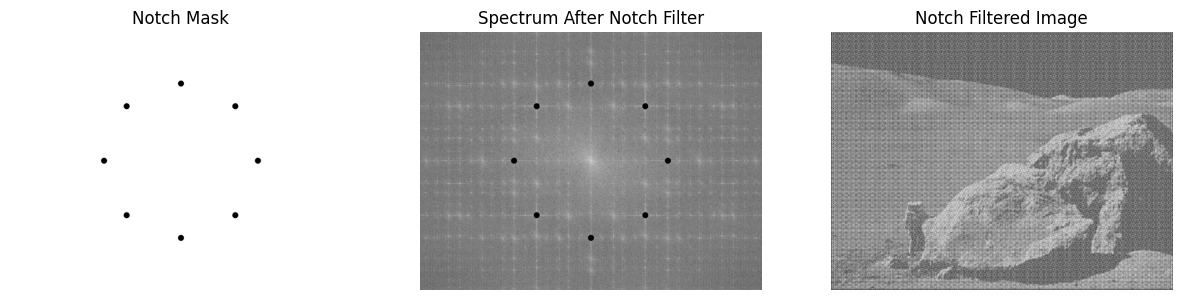

In [17]:
def detect_spectral_peaks(spectrum, cy, cx, central_skip=18, max_peaks=8, min_distance=12):
    amplitude = cv.magnitude(spectrum[:, :, 0], spectrum[:, :, 1])

    amplitude[
        cy - central_skip:cy + central_skip + 1,
        cx - central_skip:cx + central_skip + 1
    ] = 0

    dilated = cv.dilate(amplitude, np.ones((5, 5), np.uint8))
    candidates = np.where((amplitude == dilated) & (amplitude > 0))
    values = amplitude[candidates]
    order = np.argsort(values)[::-1]

    chosen_peaks = []
    for idx in order:
        y, x = candidates[0][idx], candidates[1][idx]
        if all((y - py) ** 2 + (x - px) ** 2 >= min_distance ** 2 for py, px in chosen_peaks):
            chosen_peaks.append((y, x))
        if len(chosen_peaks) >= max_peaks:
            break

    return chosen_peaks


def build_notch_mask(shape, peaks, cy, cx, radius=7):
    h, w = shape
    mask = np.ones((h, w), np.float32)

    for y, x in peaks:
        cv.circle(mask, (x, y), radius, 0, -1)

        symmetric_y = (2 * cy - y) % h
        symmetric_x = (2 * cx - x) % w

        cv.circle(mask, (symmetric_x, symmetric_y), radius, 0, -1)

    return mask


noise_peaks = detect_spectral_peaks(centered_spectrum, center_y, center_x)
notch_mask = build_notch_mask((height, width), noise_peaks, center_y, center_x)

two_channel_notch = np.dstack([notch_mask, notch_mask])
notch_spectrum = centered_spectrum * two_channel_notch
notch_image = inverse_dft(notch_spectrum)

print("Detected spectral peaks:", noise_peaks)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
show_gray(notch_mask, 'Notch Mask')

plt.subplot(1, 3, 2)
show_gray(log_magnitude(notch_spectrum), 'Spectrum After Notch Filter')

plt.subplot(1, 3, 3)
show_gray(notch_image, 'Notch Filtered Image', normalize=True)

plt.show()

# Task4 Comparison of Results

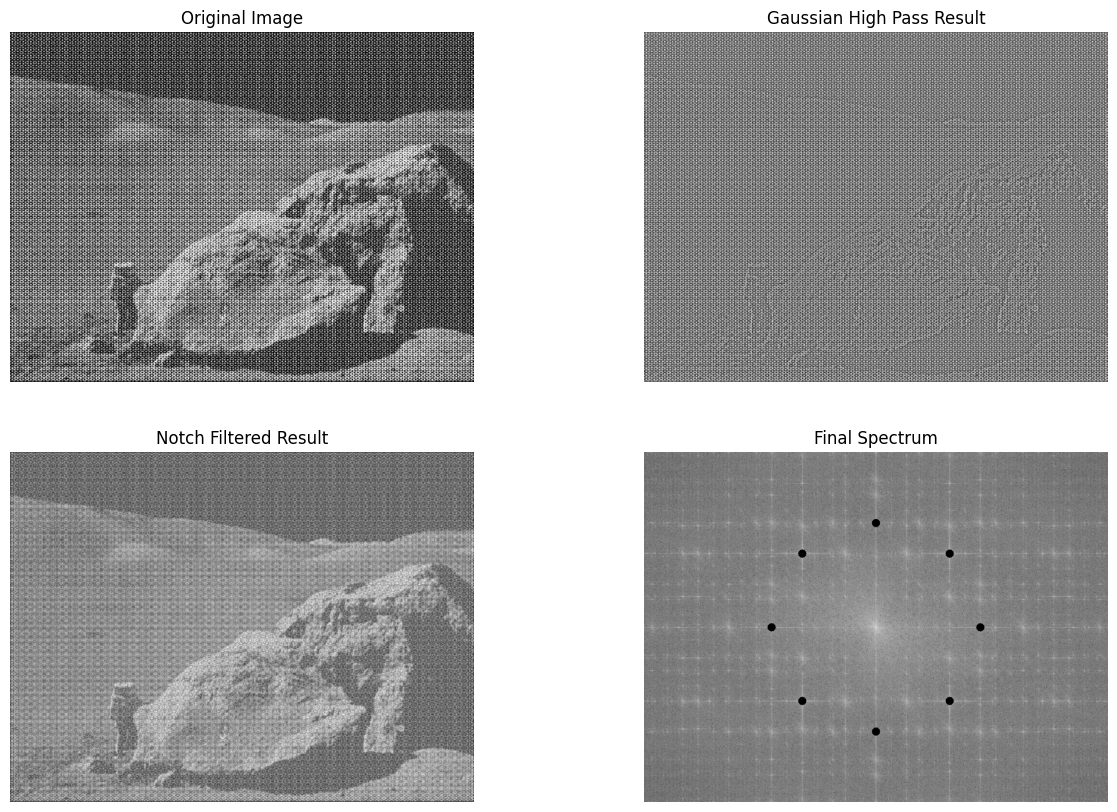

In [18]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
show_gray(source_image, 'Original Image')

plt.subplot(2, 2, 2)
show_gray(high_pass_image, 'Gaussian High Pass Result', normalize=True)

plt.subplot(2, 2, 3)
show_gray(notch_image, 'Notch Filtered Result', normalize=True)

plt.subplot(2, 2, 4)
show_gray(log_magnitude(notch_spectrum), 'Final Spectrum')

plt.show()